<a href="https://colab.research.google.com/github/umutcanc7/CS412_HW3/blob/main/CS412_HW3_Umut_Can_%C3%87ubuk%C3%A7u_32453.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS412 - Machine Learning - Fall 2025
## Homework 3


## Dataset
[**CelebA**](https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html) is a large-scale face attributes dataset with more than 200K celebrity images, each with 40 attribute annotations. The images in this dataset cover large pose variations and background clutter.

**Download the data from Sucourse and upload it to your Google Drive. You must upload both CelebA30k.zip and CelebA30k.csv to your Drive without renaming them.
CelebA30k is a smaller version of the original CelebA dataset, containing 30,000 images, to reduce computation time during training.
Split the data as follows: reserve 10% of the samples for validation and 10% for testing (i.e., 3,000 samples). The remaining 80% should be used for training.
Important: The test set (3,000 samples) must be used only for final evaluation and not for model selection or hyperparameter tuning.**

## Task

The task in this homework is to perform binary **smiling** classification on a subset of the CelebA dataset using transfer learning.

A pretrained VGG-16 model will be adapted to the task, and its performance will be evaluated under several settings. You will replace the classification head with a binary output layer and train the model for a fixed number of 10 epochs per configuration.

You must:
- Freeze appropriate parts of the pretrained model according to the strategy you choose and only modify the classification head.
- Evaluate your models using the following hyperparameters:
  - 10 epochs
  - Learning rate: 0.0001
  - Fine-tuning strategies:
    1. Freeze all convolutional layers and train only the classifier head.
    2. Freeze all weights except the last convolutional block and the classifier head, and fine-tune those parameters.
- Apply Random Horizontal Flip and a light Color Jitter during training, then discuss how these augmentations affect the smiling classification performance.

**Dataset:** CelebA  
**Model:** VGG-16  
**Library:** PyTorch  

---

## Software

You will use the PyTorch framework for this homework. PyTorch offers flexible tools for deep learning, including pretrained models, custom training loops, and GPU acceleration.


## 1) Initialize

*   First make a copy of the notebook given to you as a starter.

*   Make sure you change your runtime to GPU.

## 2) Load training dataset

In [ ]:
# load data
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
# Import necessary libraries

import numpy as np #Added to fix the error
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, models, transforms

from torch.utils.data import DataLoader, Dataset

# For reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

%matplotlib inline

In [ ]:
data = pd.read_csv('/content/drive/My Drive/CelebA30k.csv') # enter the file path on your drive for the csv file
data.head()

,filename,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,Black_Hair,...,Sideburns,Smiling,Straight_Hair,Wavy_Hair,Wearing_Earrings,Wearing_Hat,Wearing_Lipstick,Wearing_Necklace,Wearing_Necktie,Young
0,000001.jpg,-1,1,1,-1,-1,-1,-1,-1,-1,...,-1,1,1,-1,1,-1,1,-1,-1,1
1,000002.jpg,-1,-1,-1,1,-1,-1,-1,1,-1,...,-1,1,-1,-1,-1,-1,-1,-1,-1,1
2,000003.jpg,-1,-1,-1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,1,-1,-1,-1,-1,-1,1
3,000004.jpg,-1,-1,1,-1,-1,-1,-1,-1,-1,...,-1,-1,1,-1,1,-1,1,1,-1,1
4,000005.jpg,-1,1,1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,-1,-1,-1,1,-1,-1,1


In [ ]:
smile_data = data[['filename', 'Smiling']].copy() #fixed as smiling
smile_data.head()

,filename,Smiling
0,000001.jpg,1
1,000002.jpg,1
2,000003.jpg,-1
3,000004.jpg,-1
4,000005.jpg,-1


In [ ]:
import os

# Unzip ONCE into /content/data
zip_path = "/content/drive/My Drive/CelebA30k.zip"
target_dir = "/content/data/CelebA30k"

if not os.path.exists(target_dir):
    print("Extracting dataset")
    !unzip -q "{zip_path}" -d "/content/data"
    print("Extraction complete")
else:
    print("Dataset already extracted, skipping unzip.")

# Set image directory
img_dir = target_dir
print("Using dataset at:", img_dir)

Extracting dataset
Extraction complete
Using dataset at: /content/data/CelebA30k


In [ ]:
first_image_path = os.path.join("/content/data/CelebA30k/", data.loc[0, "filename"]) # there is no gender_data so i deleted it and used filename column
img = Image.open(first_image_path)

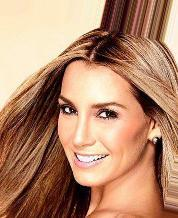

In [ ]:
img

# Starting here, you’ll need to fill in the code cells on your own.

## 3) Visualizing/Understanding the dataset

- Display five random images together with their smiling labels.
- Display statistics about the dataset, such as the distribution of smiling vs. not-smiling samples and any other attributes that you find informative.


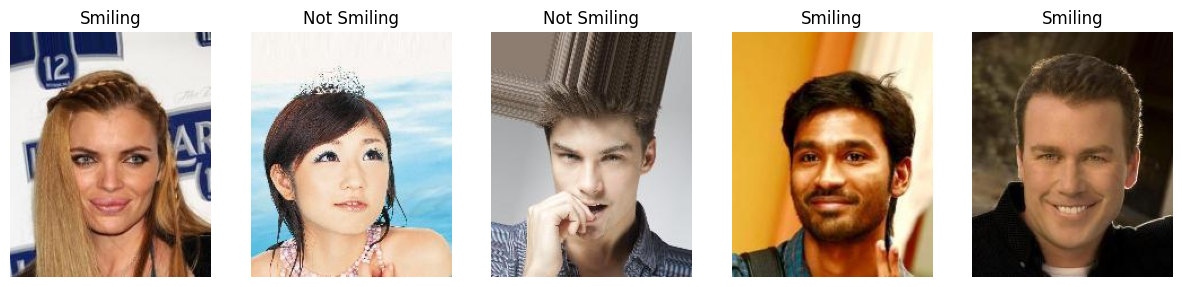

In [ ]:
import random
from IPython.display import display

# pick 5 random indices
random_indices = random.sample(range(len(data)), 5)

plt.figure(figsize=(15, 8))

for i, idx in enumerate(random_indices):
    row = data.iloc[idx]
    img_path = os.path.join(img_dir, row["filename"])
    img = Image.open(img_path)

    plt.subplot(1, 5, i+1)
    plt.imshow(img)
    plt.axis("off")
    label = "Smiling" if row["Smiling"] == 1 else "Not Smiling"
    plt.title(label)

plt.show()

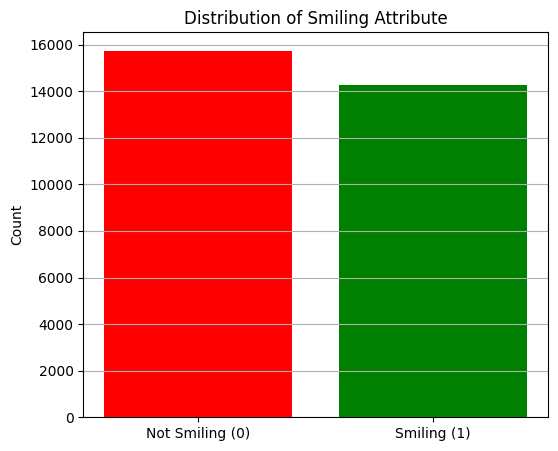

Smiling distribution:
 Smiling
-1    15741
 1    14259
Name: count, dtype: int64


In [ ]:
import matplotlib.pyplot as plt

# Count distribution
smile_counts = data["Smiling"].value_counts().sort_index()
labels = ["Not Smiling (0)", "Smiling (1)"]

plt.figure(figsize=(6,5))
plt.bar(labels, smile_counts.values, color=["red","green"])
plt.title("Distribution of Smiling Attribute")
plt.ylabel("Count")
plt.grid(axis="y")
plt.show()

print("Smiling distribution:\n", smile_counts)


Gender vs Smiling Distribution:
        Not Smiling  Smiling
Female         8053     9267
Male           7688     4992


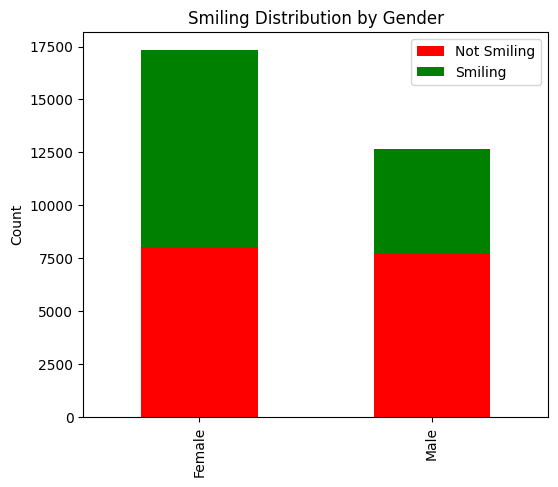

In [ ]:

if 'Male' in data.columns:
    gender_smiling = pd.crosstab(data['Male'], data['Smiling'])
    gender_smiling.index = ['Female', 'Male'] # Assuming -1=Female, 1=Male
    gender_smiling.columns = ['Not Smiling', 'Smiling']

    print("\nGender vs Smiling Distribution:")
    print(gender_smiling)

    # Visualizing it
    gender_smiling.plot(kind='bar', stacked=True, color=['red', 'green'], figsize=(6,5))
    plt.title("Smiling Distribution by Gender")
    plt.ylabel("Count")
    plt.show()

## 4) Split the dataset as train (80%), validation (10%) and test (10%) set.

In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    data,
    test_size=0.20,   # train = 80%
    random_state=42,
    stratify=data["Smiling"]   # label dengesini korumak için
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,  # 20%'yi ikiye böl: 10% val + 10% test
    random_state=42,
    stratify=temp_df["Smiling"]
)
print("Train size:", len(train_df))
print("Validation size:", len(val_df))
print("Test size:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

Train size: 24000
Validation size: 3000
Test size: 3000
Total: 30000


## 5) Preparing the Data

In this section, you will implement the dataset loading and preprocessing pipeline using PyTorch.

You are provided with:
- `train_df` and `val_df` dataframes, which include two columns: `filename`  and `Smiling`
- A directory path (`/content/data/CelebA30k`) that contains the image files

Your task is to:
1. Define appropriate transformations using `torchvision.transforms` for the training and validation sets
   - Resize images to 224x224
   - Convert them to tensors
   - Normalize them (you can use `[0.5, 0.5, 0.5]` for simplicity)
   - Include `RandomHorizontalFlip` and a light `ColorJitter` (e.g., low brightness/contrast adjustments) for the training set to satisfy the augmentation requirement
2. Write a custom `Dataset` class that reads images and smiling labels from the dataframe
3. Create `DataLoader` objects for training and validation with an appropriate batch size.
4. Keep notes on how the applied augmentations might influence the smiling classification results so you can reflect on them in your discussion


In [ ]:
# 1. Define transformations for training and validation sets

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),                         # Required image size
    transforms.RandomHorizontalFlip(p=0.5),               # Augmentation #1
    transforms.ColorJitter(brightness=0.1, contrast=0.1), # Augmentation #2
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])              # Simpler normalization (as required)
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),                        # No augmentation
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])
class CelebASmileDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

        # Raw Smiling values (-1, +1)
        raw = self.df["Smiling"].values

        # Map -1 → 0, 1 → 1
        self.labels = (raw == 1).astype("float32")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        filename = self.df.iloc[idx]["filename"]
        path = os.path.join(self.img_dir, filename)

        image = Image.open(path).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

img_dir = "/content/data/CelebA30k/"

# Create datasets
train_dataset = CelebASmileDataset(
    dataframe=train_df,
    img_dir=img_dir,
    transform=train_transforms
)

val_dataset = CelebASmileDataset(
    dataframe=val_df,
    img_dir=img_dir,
    transform=val_transforms
)

# DataLoaders
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,       # Always shuffle training data
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,      # Do NOT shuffle validation
    num_workers=2,
    pin_memory=True
)

print(f"Train loader: {len(train_loader)} batches")
print(f"Val loader: {len(val_loader)} batches")

Train loader: 375 batches
Val loader: 47 batches


## 6) Transfer Learning with VGG-16

We will create the base model from the well-known VGG-16 architecture available in torchvision.models. This model is pretrained on the ImageNet dataset, a large dataset containing 1.4 million images and 1,000 object categories.

In transfer learning, we use the convolutional base of the pretrained model as a feature extractor. However, we do not use the last fully connected layer, which is specific to ImageNet’s 1,000-class classification task. Instead, we will:
- Keep the convolutional layers (which extract general visual features)
- Remove the final classification layer
- Replace it with our own binary classifier (for smiling classification)

This is a common strategy because the layer before the original classification head (the so-called "bottleneck layer") retains high-level, general features useful for a wide range of vision tasks.

### Instructions

You should:
1. Load the VGG-16 model with weights=models.VGG16_Weights.IMAGENET1K_V1 torchvision.models.
2. Replace the classifier head with a new sequence of layers suitable for binary classification:
   - The final output should have one neuron (output dimension = 1).
   - Do not apply a Sigmoid activation after the output layer, because the loss function you will use internally applies it.


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
import time
import matplotlib.pyplot as plt


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Load pretrained VGG-16
vgg_base = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)

# Replace final FC layer (4096 → 1)
num_features = vgg_base.classifier[6].in_features
vgg_base.classifier[6] = nn.Linear(num_features, 1)

vgg_base = vgg_base.to(device)

criterion = nn.BCEWithLogitsLoss()
print(vgg_base.classifier)
print(f"\nModel moved to: {device}")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:05<00:00, 103MB/s] 


Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=4096, out_features=4096, bias=True)
  (4): ReLU(inplace=True)
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=4096, out_features=1, bias=True)
)

Model moved to: cuda


## 7) Fine-Tuning and Training the Model

Now that your VGG-16 base model is set up with a new binary classification head, it’s time to fine-tune and train it using your `train_loader` and evaluate it using your `val_loader`.

You will:

- Experiment with the two required fine-tuning strategies:
  - Freeze all convolutional layers and train only the classifier head.
  - Unfreeze the last convolutional block together with the classifier head and fine-tune those parameters while keeping the earlier layers frozen.
- Use `nn.BCEWithLogitsLoss()` as the loss function and choose an appropriate optimizer (e.g., `torch.optim.SGD` or `Adam`).
- For each fine-tuning strategy, train models with `learning rate = 0.0001`). Each configuration must run for exactly 10 epochs with the mandated data augmentation pipeline.
- Implement a training loop that includes validation after each epoch and monitor both training and validation performance across epochs.
- Keep track of the training duration and include it in your reports.
- You may adjust batch size depending on available GPU memory, but typically 32 or 64 is suggested.

**Reporting requirements:**

- Final training and validation accuracy for both configurations.
- Plots for each setup, showing training and validation loss across epochs.
- A table showing training-validation loss, accuracy, and training duration of the models.
- A discussion regarding:
  1. Which fine-tuning strategy performed best and why,
  2. How the Random Horizontal Flip + Color Jitter augmentation influenced the results.


**Note:** Normally, this setup is not optimal for hyperparameter tuning and you would want to experiment with different learning rates, batch sizes, freezing strategies etc. The tuned parameters were kept limited to have reasonable training times and GPU consumptions in this study. If you are curious, you are more than welcome to experiment with other parameters. Especially, `learning rate = 0.001` gives interesting results when used in a fine-tuned model (i.e. when the last convolutional block is not frozen).   


In [ ]:
def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct, total = 0, 0, 0

    for X, y in loader:
        X = X.to(device)
        y = y.to(device).float()

        optimizer.zero_grad()
        logits = model(X).squeeze(1)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X.size(0)

        preds = (torch.sigmoid(logits) >= 0.5).long()
        correct += (preds == y.long()).sum().item()
        total += X.size(0)

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0

    for X, y in loader:
        X = X.to(device)
        y = y.to(device).float()

        logits = model(X).squeeze(1)
        loss = criterion(logits, y)

        total_loss += loss.item() * X.size(0)
        preds = (torch.sigmoid(logits) >= 0.5).long()
        correct += (preds == y.long()).sum().item()
        total += X.size(0)

    return total_loss / total, correct / total

In [ ]:
import time

# STRATEGY 1 MODEL
vgg_s1 = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
vgg_s1.classifier[6] = nn.Linear(vgg_s1.classifier[6].in_features, 1)

# Freeze ALL convolutional layers
for param in vgg_s1.features.parameters():
    param.requires_grad = False

vgg_s1 = vgg_s1.to(device)

optimizer_s1 = optim.Adam(vgg_s1.classifier.parameters(), lr=0.0001)
history_s1 = {"train_loss":[], "val_loss":[], "train_acc":[], "val_acc":[]}

print("===========================================================")
print("Training Strategy 1 (Frozen) - With Augmentation")
print("===========================================================\n")

# --- START TIMER ---
start_time = time.perf_counter()

for epoch in range(1, 11):
    tr_loss, tr_acc = train_one_epoch(vgg_s1, train_loader, optimizer_s1)
    val_loss, val_acc = evaluate(vgg_s1, val_loader)

    history_s1["train_loss"].append(tr_loss)
    history_s1["val_loss"].append(val_loss)
    history_s1["train_acc"].append(tr_acc)
    history_s1["val_acc"].append(val_acc)

    print(f"Epoch {epoch}/10")
    print("---------------------------------------")
    print(f"Train Loss: {tr_loss:.4f} | Train Acc: {tr_acc:.4f}")
    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f}\n")

# --- END TIMER ---
duration_s1 = time.perf_counter() - start_time
print(f"Training complete in {duration_s1/60:.2f} min")

Training Strategy 1 (Frozen) - With Augmentation

Epoch 1/10
---------------------------------------
Train Loss: 0.4191 | Train Acc: 0.7997
Val Loss:   0.3397 | Val Acc:   0.8500

Epoch 2/10
---------------------------------------
Train Loss: 0.3133 | Train Acc: 0.8617
Val Loss:   0.3159 | Val Acc:   0.8617

Epoch 3/10
---------------------------------------
Train Loss: 0.2672 | Train Acc: 0.8864
Val Loss:   0.3313 | Val Acc:   0.8543

Epoch 4/10
---------------------------------------
Train Loss: 0.2311 | Train Acc: 0.9027
Val Loss:   0.3621 | Val Acc:   0.8513

Epoch 5/10
---------------------------------------
Train Loss: 0.1971 | Train Acc: 0.9196
Val Loss:   0.3444 | Val Acc:   0.8587

Epoch 6/10
---------------------------------------
Train Loss: 0.1674 | Train Acc: 0.9330
Val Loss:   0.3721 | Val Acc:   0.8643

Epoch 7/10
---------------------------------------
Train Loss: 0.1361 | Train Acc: 0.9454
Val Loss:   0.4010 | Val Acc:   0.8583

Epoch 8/10
-----------------------------

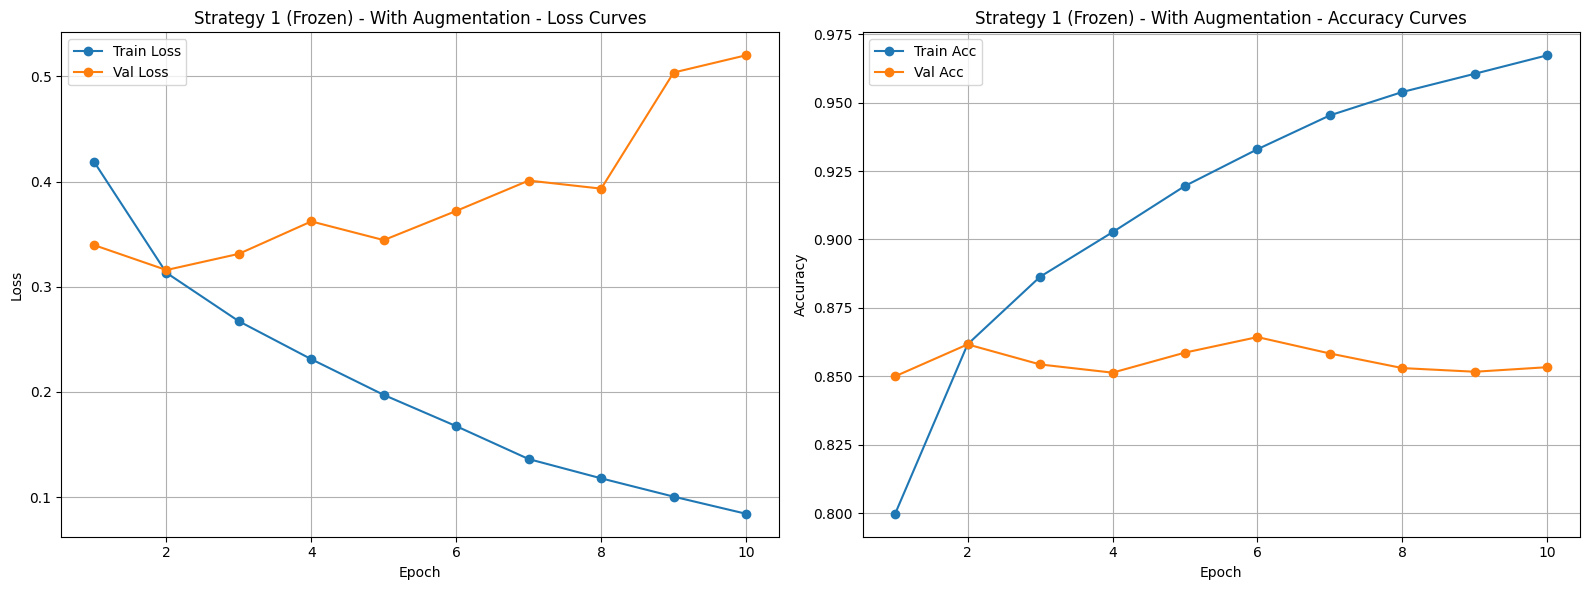

In [ ]:
epochs = range(1, len(history_s1["train_loss"]) + 1)

plt.figure(figsize=(16, 6))

# ---------------- LOSS CURVE ----------------
plt.subplot(1, 2, 1)
plt.plot(epochs, history_s1["train_loss"], label="Train Loss", marker='o')
plt.plot(epochs, history_s1["val_loss"], label="Val Loss", marker='o')
plt.title("Strategy 1 (Frozen) - With Augmentation - Loss Curves")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

# ---------------- ACCURACY CURVE ----------------
plt.subplot(1, 2, 2)
plt.plot(epochs, history_s1["train_acc"], label="Train Acc", marker='o')
plt.plot(epochs, history_s1["val_acc"], label="Val Acc", marker='o')
plt.title("Strategy 1 (Frozen) - With Augmentation - Accuracy Curves")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ===========================================================
# Training Strategy 2 (Unfreeze Last Conv Block + Classifier)
# ===========================================================

# Load fresh pretrained VGG16
vgg_s2 = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)

# Replace classifier head for binary classification
num_features = vgg_s2.classifier[6].in_features
vgg_s2.classifier[6] = nn.Linear(num_features, 1)

# Freeze all layers first
for p in vgg_s2.parameters():
    p.requires_grad = False

# Unfreeze last convolutional block (layers 24 to 30)
for p in vgg_s2.features[24:].parameters():
    p.requires_grad = True

# Unfreeze classifier
for p in vgg_s2.classifier.parameters():
    p.requires_grad = True

vgg_s2 = vgg_s2.to(device)

# Optimizer only updates trainable params
optimizer_s2 = optim.Adam(
    filter(lambda p: p.requires_grad, vgg_s2.parameters()),
    lr=0.0001
)

num_epochs = 10
history_s2 = {"train_loss":[], "val_loss":[], "train_acc":[], "val_acc":[]}

print("\n===========================================================")
print("Training Strategy 2 (Unfreeze Last Block) - With Augmentation")
print("===========================================================\n")

start_time = time.perf_counter()

for epoch in range(num_epochs):

    print(f"Epoch {epoch+1}/{num_epochs}")
    print("---------------------------------------")

    # ❗ FIXED: device arg removed
    train_loss, train_acc = train_one_epoch(vgg_s2, train_loader, optimizer_s2)
    val_loss, val_acc = evaluate(vgg_s2, val_loader)

    history_s2["train_loss"].append(train_loss)
    history_s2["val_loss"].append(val_loss)
    history_s2["train_acc"].append(train_acc)
    history_s2["val_acc"].append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f}\n")

duration_s2 = time.perf_counter() - start_time
print(f"Training complete in {duration_s2/60:.2f} min")
print(f"Best Validation Accuracy: {max(history_s2['val_acc']):.4f}")


Training Strategy 2 (Unfreeze Last Block) - With Augmentation

Epoch 1/10
---------------------------------------
Train Loss: 0.2738 | Train Acc: 0.8813
Val Loss:   0.1910 | Val Acc:   0.9163

Epoch 2/10
---------------------------------------
Train Loss: 0.1931 | Train Acc: 0.9194
Val Loss:   0.1939 | Val Acc:   0.9093

Epoch 3/10
---------------------------------------
Train Loss: 0.1668 | Train Acc: 0.9309
Val Loss:   0.1975 | Val Acc:   0.9233

Epoch 4/10
---------------------------------------
Train Loss: 0.1430 | Train Acc: 0.9414
Val Loss:   0.2041 | Val Acc:   0.9187

Epoch 5/10
---------------------------------------
Train Loss: 0.1165 | Train Acc: 0.9529
Val Loss:   0.2377 | Val Acc:   0.9147

Epoch 6/10
---------------------------------------
Train Loss: 0.0949 | Train Acc: 0.9621
Val Loss:   0.2626 | Val Acc:   0.9157

Epoch 7/10
---------------------------------------
Train Loss: 0.0701 | Train Acc: 0.9728
Val Loss:   0.2702 | Val Acc:   0.9057

Epoch 8/10
---------------

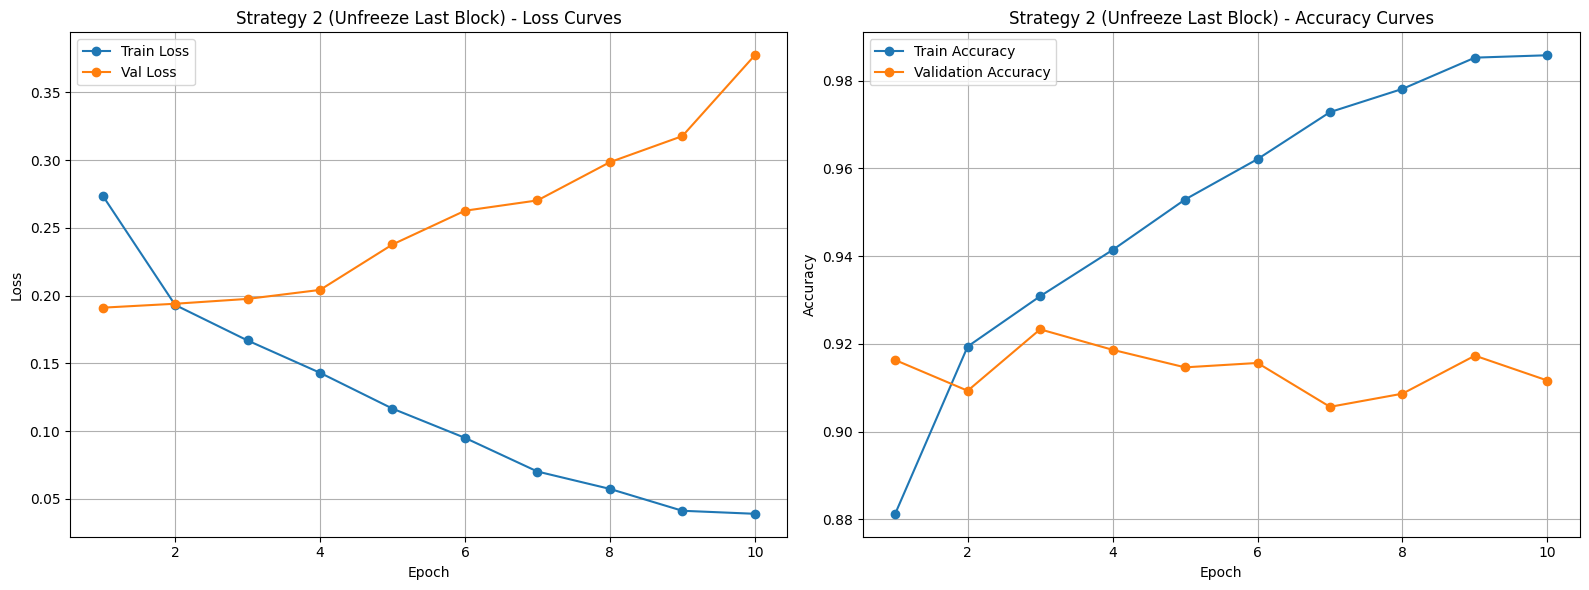

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(history_s2["train_loss"]) + 1)

plt.figure(figsize=(16, 6))

# ---------------- LOSS CURVE ----------------
plt.subplot(1, 2, 1)
plt.plot(epochs, history_s2["train_loss"], label="Train Loss", marker='o')
plt.plot(epochs, history_s2["val_loss"], label="Val Loss", marker='o')
plt.title("Strategy 2 (Unfreeze Last Block) - Loss Curves")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

# ---------------- ACCURACY CURVE ----------------
plt.subplot(1, 2, 2)
plt.plot(epochs, history_s2["train_acc"], label="Train Accuracy", marker='o')
plt.plot(epochs, history_s2["val_acc"], label="Validation Accuracy", marker='o')
plt.title("Strategy 2 (Unfreeze Last Block) - Accuracy Curves")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Helper function to get metrics from the best epoch
def get_best_metrics(history, duration):
    # Find the index (epoch) with the highest Validation Accuracy
    best_epoch_idx = history['val_acc'].index(max(history['val_acc']))

    return {
        "Best Epoch": best_epoch_idx + 1,
        "Train Loss": history['train_loss'][best_epoch_idx],
        "Val Loss": history['val_loss'][best_epoch_idx],
        "Train Acc": history['train_acc'][best_epoch_idx],
        "Val Acc": history['val_acc'][best_epoch_idx],
        "Duration (min)": duration / 60
    }

# Extract data for both strategies
# (Assuming duration_s1 and duration_s2 were calculated in previous steps)
metrics_s1 = get_best_metrics(history_s1, duration_s1)
metrics_s2 = get_best_metrics(history_s2, duration_s2)

# Create DataFrame
df_results = pd.DataFrame([metrics_s1, metrics_s2],
                          index=["Strategy 1 (Frozen)", "Strategy 2 (Fine-Tune)"])

# Display the table
print("=========================================")
print("      FINAL PERFORMANCE SUMMARY")
print("=========================================")
display(df_results.round(4)) # Round to 4 decimal places for cleanliness

      FINAL PERFORMANCE SUMMARY


,Best Epoch,Train Loss,Val Loss,Train Acc,Val Acc,Duration (min)
Strategy 1 (Frozen),6,0.1674,0.3721,0.9330,0.8643,24.0917
Strategy 2 (Fine-Tune),3,0.1668,0.1975,0.9309,0.9233,25.8618


## 8) Test your classifier on Test set

- Determine the setup with the best performance based on validation set performance.
- Use your model to predict the labels of the test set and report the final accuracy.
- Display the confusion matrix.
- Display 5 correct, 5 incorrect classifications.
- Include the findings in your report, and ensure that the distinction between training and test results is clearly distinguishable.


In [ ]:
# Create test dataset
test_dataset = CelebASmileDataset(
    dataframe=test_df,
    img_dir=img_dir,
    transform=val_transforms   # same as validation transforms
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Test loader ready.")

Test loader ready.


In [ ]:
def evaluate_test(model, loader, device):
    model.eval()
    correct = 0
    total = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for X, y in loader:
            X = X.to(device)
            y = y.to(device).float()

            # SAFEGUARD: Use squeeze(1) instead of squeeze()
            logits = model(X).squeeze(1)
            preds = (torch.sigmoid(logits) >= 0.5).float()

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())

            correct += (preds == y).sum().item()
            total += y.size(0)

    acc = correct / total
    return acc, all_preds, all_labels

In [ ]:
val_acc_1 = max(history_s1['val_acc'])
val_acc_2 = max(history_s2['val_acc'])

if val_acc_2 > val_acc_1:
    print(f"Strategy 2 is better ({val_acc_2:.4f} vs {val_acc_1:.4f})")
    best_model = vgg_s2
else:
    print(f"Strategy 1 is better ({val_acc_1:.4f} vs {val_acc_2:.4f})")
    best_model = vgg_s1

# Evaluate the better val
test_acc, test_preds, test_labels = evaluate_test(best_model, test_loader, device)
print(f"\nFinal Test Accuracy: {test_acc:.4f}")

Strategy 2 is better (0.9233 vs 0.8643)

Final Test Accuracy: 0.9147


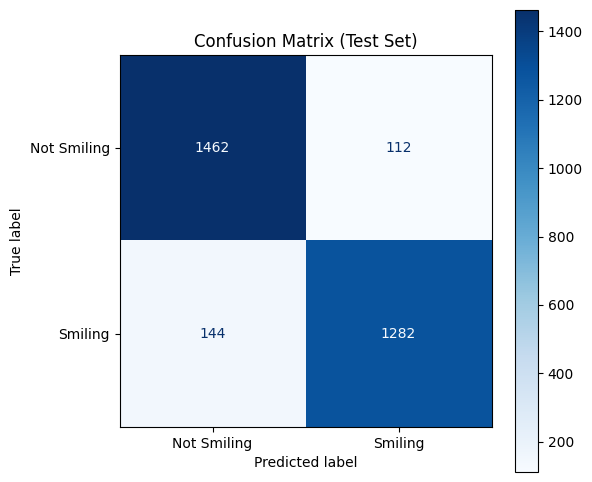

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(test_labels, test_preds)


fig, ax = plt.subplots(figsize=(6, 6))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Smiling", "Smiling"])
disp.plot(cmap="Blues", values_format="d", ax=ax)
plt.title("Confusion Matrix (Test Set)")
plt.show()


Showing 5 Correct Predictions:



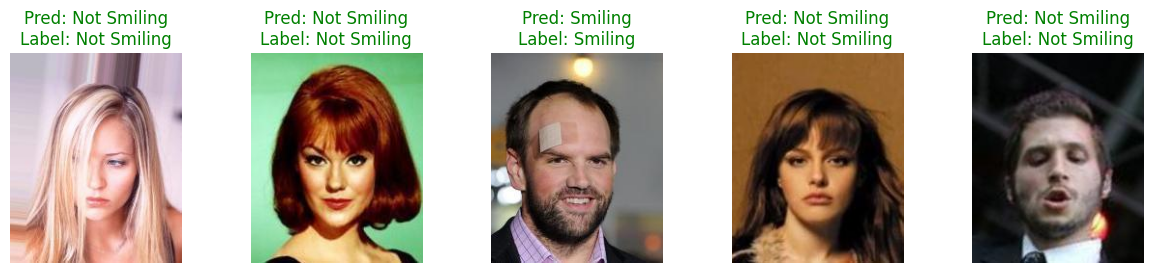


Showing 5 Incorrect Predictions:



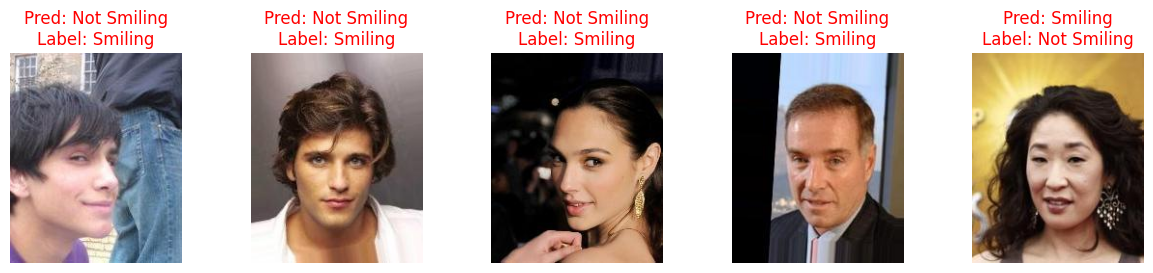

In [ ]:
import random
from PIL import Image

# Define the mapping for better readability
class_names = {0: "Not Smiling", 1: "Smiling"}

correct_samples = []
incorrect_samples = []

test_df_reset = test_df.reset_index()

for i in range(len(test_labels)):
    if test_preds[i] == test_labels[i] and len(correct_samples) < 5:
        correct_samples.append(i)
    elif test_preds[i] != test_labels[i] and len(incorrect_samples) < 5:
        incorrect_samples.append(i)

# ---- Correct samples ----
print("\nShowing 5 Correct Predictions:\n")
plt.figure(figsize=(15, 6)) # Increased width slightly for text
for idx, sample_idx in enumerate(correct_samples):
    filename = test_df_reset.loc[sample_idx, "filename"]
    img_path = os.path.join(img_dir, filename)
    img = Image.open(img_path)

    plt.subplot(2, 5, idx+1)
    plt.imshow(img)
    plt.axis("off")

    # CHANGED HERE: Map 0/1 to Text
    pred_text = class_names[int(test_preds[sample_idx])]
    label_text = class_names[int(test_labels[sample_idx])]
    plt.title(f"Pred: {pred_text}\nLabel: {label_text}", color='green')

plt.show()

# ---- Incorrect samples ----
print("\nShowing 5 Incorrect Predictions:\n")
plt.figure(figsize=(15, 6)) # Increased width slightly for text
for idx, sample_idx in enumerate(incorrect_samples):
    filename = test_df_reset.loc[sample_idx, "filename"]
    img_path = os.path.join(img_dir, filename)
    img = Image.open(img_path)

    plt.subplot(2, 5, idx+1)
    plt.imshow(img)
    plt.axis("off")

    # CHANGED HERE: Map 0/1 to Text
    pred_text = class_names[int(test_preds[sample_idx])]
    label_text = class_names[int(test_labels[sample_idx])]
    plt.title(f"Pred: {pred_text}\nLabel: {label_text}", color='red')

plt.show()